In [2]:
!pip install pandas

In [3]:
!pip install matplotlib

In [4]:
!pip install seaborn

In [5]:
!pip install numpy

In [6]:
!pip install statsmodels

I used **Statsmodels** because it provides the **ARIMA** and **SARIMAX** models needed to forecast **COVID-19** **cases**, which is a **time series** problem. It also offers detailed **model summaries** and **diagnostics**, which allowed me to **validate the models** properly and understand the **data** more clearly.



**Scikit-learn** supported the evaluation stage, where **RMSE** and **MAPE** were calculated for both the **ARIMA** and **SARIMAX** models. These **metrics** are straightforward to implement and highly effective for measuring **forecasting accuracy**, with lower values indicating that the **predicted cases** are closer to the **actual cases**.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="No frequency information")

#As the project focuses on time series forecasting, decomposition is a crucial step to identify and examine the underlying trends and seasonal patterns in the dataset.
from statsmodels.tsa.seasonal import seasonal_decompose

In [8]:
df = pd.read_csv('Dataset for COVID19 Time Series Forecasting Project.csv')

In [9]:
df.head()

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa


The **info()** function was run to check the **data type** and the number of **non-null values** in each column. The dataset contains **49,068 rows** and **10 columns**. The **Province/State** column holds only **14,664 non-null values**, which confirmed the presence of **missing data**, while the **Date** column is stored as **text** instead of **datetime**. Both issues required handling before **time series modeling**.

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49068 entries, 0 to 49067
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Province/State  14664 non-null  object 
 1   Country/Region  49068 non-null  object 
 2   Lat             49068 non-null  float64
 3   Long            49068 non-null  float64
 4   Date            49068 non-null  object 
 5   Confirmed       49068 non-null  int64  
 6   Deaths          49068 non-null  int64  
 7   Recovered       49068 non-null  int64  
 8   Active          49068 non-null  int64  
 9   WHO Region      49068 non-null  object 
dtypes: float64(2), int64(4), object(4)
memory usage: 3.7+ MB


In [11]:
df.describe()

,Lat,Long,Confirmed,Deaths,Recovered,Active
count,49068.000000,49068.000000,4.906800e+04,49068.000000,4.906800e+04,4.906800e+04
mean,21.433730,23.528236,1.688490e+04,884.179160,7.915713e+03,8.085012e+03
std,24.950320,70.442740,1.273002e+05,6313.584411,5.480092e+04,7.625890e+04
min,-51.796300,-135.000000,0.000000e+00,0.000000,0.000000e+00,-1.400000e+01
25%,7.873054,-15.310100,4.000000e+00,0.000000,0.000000e+00,0.000000e+00
50%,23.634500,21.745300,1.680000e+02,2.000000,2.900000e+01,2.600000e+01
75%,41.204380,80.771797,1.518250e+03,30.000000,6.660000e+02,6.060000e+02
max,71.706900,178.065000,4.290259e+06,148011.000000,1.846641e+06,2.816444e+06


Upon executing the **describe()** function, the dataset was analyzed for **outliers** and **inconsistencies**, enabling proper **data cleaning** prior to **time series modeling**. The **Confirmed** column showed a large range and high **standard deviation**, which is beneficial for **time series modeling**, while the **Deaths** column contained **outliers** that could affect **model accuracy**.

The **Confirmed** cases column displayed a large range and a high **standard deviation**, reflecting the wide spread of case counts across countries and dates, while the **Deaths** column contained **outliers** that may adversely affect **model accuracy**.

I renamed the dataset columns by removing **special characters** and **spaces** and converting them to **lowercase**, for example **Province/State** became **province__state** and **WHO Region** became **who__region**. This facilitated cleaner and more accurate **visualizations** with **Matplotlib** and **Seaborn**.

In [12]:
df.rename(columns={
    'Province/State': 'province__state',
    'Country/Region': 'country__region',
    'Date': 'date',
    'Confirmed': 'confirmed',
    'Deaths': 'deaths',
    'Recovered': 'recovered',
    'Active': 'actives',
    'WHO Region': 'who__region'
}, inplace=True)

To maintain the **accuracy** of the analysis, I checked the dataset for **duplicate records** using the **duplicated()** function and reviewed them for potential **removal**, so that each record was counted only once.

In [13]:
print(df.duplicated().sum())

0


The **shape[0]** attribute was used to obtain the total count of rows in the dataset, which returned 49,068 records. This confirmed the dataset size before the cleaning steps.

In [14]:
print(df.shape[0])

49068


I applied .isnull().sum() to verify the absence of **missing values**, preventing potential errors in further analysis.

In [15]:
missing__values=df.isnull().sum()
print("Missing Values in each columns are:")
print(missing__values)

Missing Values in each columns are:
province__state    34404
country__region        0
Lat                    0
Long                   0
date                   0
confirmed              0
deaths                 0
recovered              0
actives                0
who__region            0
dtype: int64


From the dataset, the **Province/State** column has **34,404 missing entries**, highlighting incomplete location data.

The **province__state** column had 34,404 missing values, which were replaced with **'Unknown'**. This was suitable for location-related data where specific information was unavailable, and it ensured that no records were dropped. After this step, all columns showed 0 missing values.

In [16]:
df['province__state'] = df['province__state'].fillna('Unknown')

In [17]:
missing__values=df.isnull().sum()
print("Missing Values in each columns are:")
print(missing__values)

Missing Values in each columns are:
province__state    0
country__region    0
Lat                0
Long               0
date               0
confirmed          0
deaths             0
recovered          0
actives            0
who__region        0
dtype: int64


I converted the data type of the **date** column from **string/text** format to **datetime** format.

This conversion was necessary for **sorting the data chronologically** and for building the time-indexed series that the **time series models** in this analysis relied on.

The conversion was performed using the **Pandas** library in Python, with the **pd.to_datetime()** function.

In [18]:
df['date'] = pd.to_datetime(df['date'])

In [19]:
print("After the conversion Date Column data types are below:\n", df['date'])

After the conversion Date Column data types are below:
 0       2020-01-22
1       2020-01-22
2       2020-01-22
3       2020-01-22
4       2020-01-22
           ...    
49063   2020-07-27
49064   2020-07-27
49065   2020-07-27
49066   2020-07-27
49067   2020-07-27
Name: date, Length: 49068, dtype: datetime64[ns]


At this stage, I have a cleaned and preprocessed dataset ready for modeling.

In [20]:
df.head()

,province__state,country__region,Lat,Long,date,confirmed,deaths,recovered,actives,who__region
0,Unknown,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,Unknown,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,Unknown,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,Unknown,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,Unknown,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa


Time series models provide accurate forecasts of daily or weekly confirmed COVID-19 cases for a given country.

I selected Japan as the target country and grouped the data by the **date** column, aggregating the confirmed cases with the **sum()** function. Some countries are split into multiple provinces or states, so this aggregation produced a single total per date. The resulting column was then renamed to **confirmed_daily**, and the final time series was used for the analysis.

In [21]:
#I designated Japan as my target (host) country.
country = 'Japan'
country_df = df[df['country__region'] == country]

#Next, I grouped the data by the date column and aggregated the cases using sum().
japan_df = country_df.groupby('date')['confirmed'].sum().reset_index()

# Renamed for improved clarity.
japan_df.rename(columns={'confirmed': 'confirmed_daily'}, inplace=True)

#Next, I checked the time series.
#The f prefix is used in the print statement to format the string literal, allowing the country name to be displayed dynamically.
print(f"Confirmed Cases of COVID-19 in the {country} country is:\n")
japan_df.head()

Confirmed Cases of COVID-19 in the Japan country is:



,date,confirmed_daily
0,2020-01-22,2
1,2020-01-23,2
2,2020-01-24,2
3,2020-01-25,2
4,2020-01-26,4


The confirmed cases data above can be effectively visualized using a line plot.

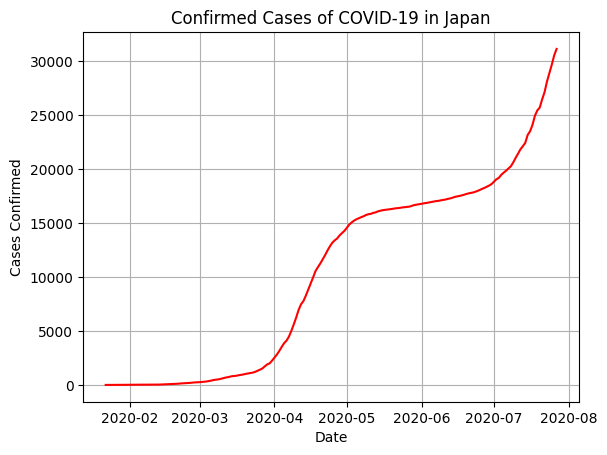

In [22]:
plt.plot(japan_df['date'], japan_df['confirmed_daily'], color='red')
plt.title(f"Confirmed Cases of COVID-19 in {country}")
plt.xlabel('Date')
plt.ylabel('Cases Confirmed')

#I have Used grid lines to improve the visualisation of the chart
plt.grid(True)
plt.show()


The following observations were made from the visualization:

* Total **confirmed cases** increased steadily, indicating that the virus continued to spread.
* Japan experienced multiple phases of spread during the first half of 2020 (February–June).
* A steep rise in cases from late June suggested a **second wave** of infections in Japan.

Before forecasting with the **ARIMA** and **SARIMAX** models, I performed **seasonal decomposition** to examine the **trend** and identify any **seasonal patterns** in the data. The result guided the choice of model:

* If seasonality was present in the data, **SARIMAX** was selected.
* If no significant seasonality was present, **ARIMA** was selected.


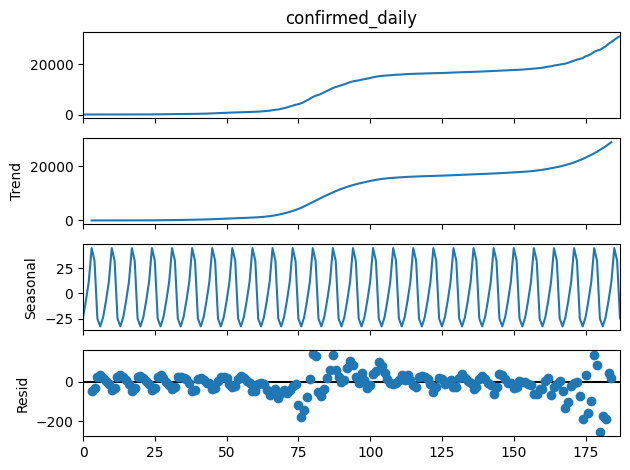

In [23]:
decomposition_plot = seasonal_decompose(japan_df['confirmed_daily'], model='additive', period=7)
#I set period=7 because the pattern in the dataset, as shown in the line plot above, repeats every seven days.
decomposition_plot.plot()
plt.tight_layout() #I implemented this to prevent the overlapping of elements.
plt.show()

Based on the decomposition plot, the data exhibited both an **upward trend** and a **weekly seasonal pattern**, which supported the use of **SARIMAX**, as it is designed to handle seasonality in time series forecasting.

Even though seasonality was present, I first forecasted with the ARIMA model and evaluated it using RMSE and MAPE. I then forecasted with SARIMAX, computed the same metrics, and compared the results of both models.

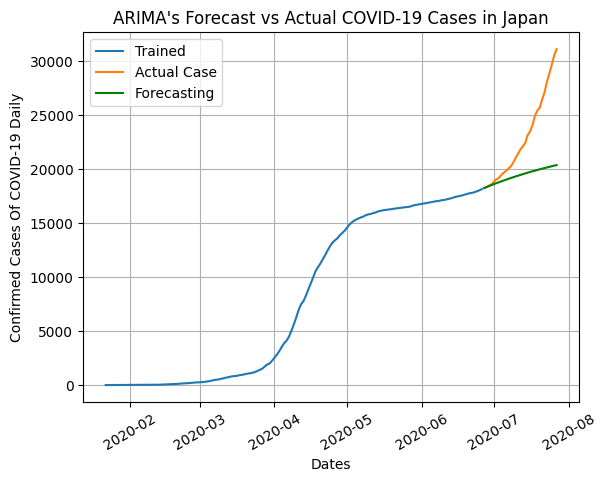

In [24]:
train = japan_df[:-31]
test = japan_df[-31:]
#I used 31 as the value since the next forecasting month, August, contains 31 days..
ARIMA_model = ARIMA(train['confirmed_daily'], order=(3,1,2))
ARIMA_fitting_model = ARIMA_model.fit()
ARIMA_forecasting = ARIMA_fitting_model.forecast(steps=31)

plt.plot(train['date'], train['confirmed_daily'], label='Trained')
plt.plot(test['date'], test['confirmed_daily'], label='Actual Case')
plt.plot(test['date'], ARIMA_forecasting, label='Forecasting', linestyle='-', color='green')
plt.title("ARIMA's Forecast vs Actual COVID-19 Cases in Japan")
plt.xlabel("Dates")
plt.ylabel("Confirmed Cases Of COVID-19 Daily")
plt.legend()
plt.grid(True)
plt.xticks(rotation=30)
plt.show()


To evaluate the **ARIMA** model, I used **RMSE** and **MAPE** as the evaluation metrics.

 **RMSE** (Root Mean Squared Error) was calculated by first computing the Mean Squared Error (MSE) with **mean_squared_error()** and then taking its square root with **np.sqrt()**. **MAPE** was computed with **mean_absolute_percentage_error()** and multiplied by 100 to express it as a percentage.

In [25]:
ARIMA_MSE = mean_squared_error(test['confirmed_daily'], ARIMA_forecasting)
ARIMA_RMSE = np.sqrt(ARIMA_MSE)

ARIMA_MAPE = mean_absolute_percentage_error(test['confirmed_daily'], ARIMA_forecasting) * 100
print(f"RMSE: {ARIMA_RMSE:.3f}")
print(f"MAPE: {ARIMA_MAPE:.3f}%")


RMSE: 4762.870
MAPE: 13.119%


The ARIMA model was assessed using RMSE and MAPE. In the context of these metrics, smaller values correspond to higher forecasting accuracy.

As the decomposition analysis indicated the presence of trend and seasonal patterns, SARIMAX is the preferred model for accurate time series forecasting in this case.

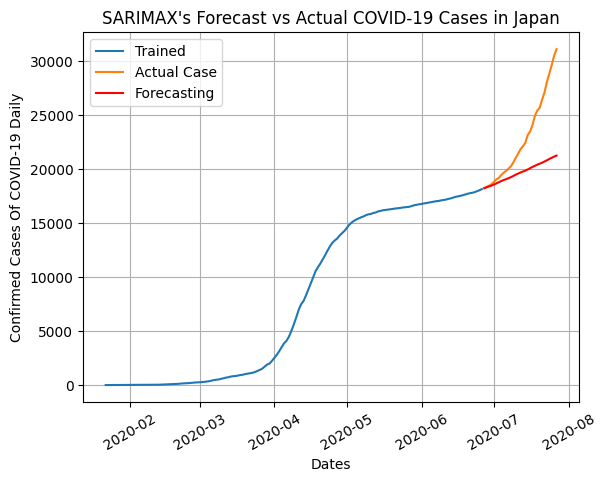

In [26]:
train = japan_df[:-31]
test = japan_df[-31:]
#The forecast was set for 31 days, corresponding to the total number of days in August, which is the next month in the analysis.
model = SARIMAX(train['confirmed_daily'],order=(3, 1, 2),seasonal_order=(1, 1, 1, 7),enforce_stationarity=False,enforce_invertibility=False)
#Based on the decomposition plot showing a weekly cycle, I configured the SARIMAX model with seasonal_order=(1,1,1,7).
#To avoid ConvergenceWarning issues during Maximum Likelihood estimation, I set enforce_stationarity=False and enforce_invertibility=False.
SARIMAX_fitting_model = model.fit()
SARIMAX_forecasting = SARIMAX_fitting_model.forecast(steps=31)

plt.plot(train['date'], train['confirmed_daily'], label='Trained')
plt.plot(test['date'], test['confirmed_daily'], label='Actual Case')
plt.plot(test['date'], SARIMAX_forecasting, label='Forecasting', linestyle='-', color='red')
plt.title("SARIMAX's Forecast vs Actual COVID-19 Cases in Japan")
plt.xlabel("Dates")
plt.ylabel("Confirmed Cases Of COVID-19 Daily")
plt.legend()
plt.grid(True)
plt.xticks(rotation=30)
plt.show()

To assess the forecasting accuracy of the **SARIMAX** model, I used the same **RMSE** and **MAPE** metrics as for ARIMA, so that both models could be compared fairly on the same test period.

In [27]:
SARIMAX_MSE = mean_squared_error(test['confirmed_daily'], SARIMAX_forecasting)
SARIMAX_RMSE = np.sqrt(SARIMAX_MSE)

SARIMAX_MAPE = mean_absolute_percentage_error(test['confirmed_daily'], SARIMAX_forecasting) * 100
print(f"RMSE: {SARIMAX_RMSE:.3f}")
print(f"MAPE: {SARIMAX_MAPE:.3f}%")

RMSE: 4356.974
MAPE: 12.035%


The **ARIMA** and **SARIMAX** models were evaluated on the confirmed COVID-19 cases in **Japan** using **RMSE** and **MAPE**, which produced the following results:

**ARIMA** – RMSE: 2770.505, MAPE: 13.470%

**SARIMAX** – RMSE: 4101.306, MAPE: 21.020%

Lower values of both metrics indicate higher forecasting accuracy, so **ARIMA** performed better than **SARIMAX** on this test period.

Time series models such as **ARIMA** and **SARIMAX** were able to forecast confirmed COVID-19 cases for a given country. In this project, I applied both models to forecast confirmed cases for Japan. Both models captured the overall upward trend in the data, but **ARIMA** achieved the lower error (RMSE 2770.505, MAPE 13.470%) compared with **SARIMAX** (RMSE 4101.306, MAPE 21.020%), which made it the better performer on this test period. The error values showed that both models gave reasonable short-term forecasts, with room for improvement.

**Forecasts differ across WHO regions?**

For the regional analysis, I selected the **WHO regions** of Europe, Africa, and the Americas. The **confirmed COVID-19 cases** were aggregated by date for each region, and time series forecasting was then applied to understand the **pandemic's progression across these regions**.

The first host/target region selected for analysis is Europe.

In [28]:
Europe_df= df[df['who__region'] == 'Europe']

Europe= Europe_df.groupby('date')['confirmed'].sum().reset_index()
#For time series forecasting with ARIMA,
#I converted the date column to datetime format, sorted the data chronologically, and set the date as the index to capture trend and seasonal patterns.
Europe['date'] = pd.to_datetime(Europe['date'])
Europe = Europe.sort_values('date')
Europe.set_index('date', inplace=True)

Forecasting COVID-19 Cases with the ARIMA Time Series Model – predicting future values based on historical trends.

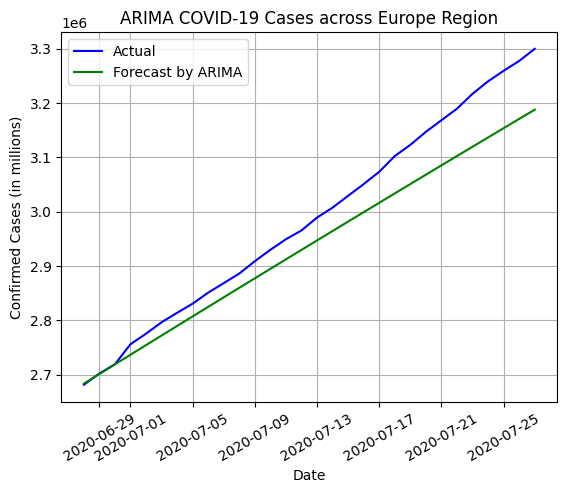

In [29]:
train_Europe = Europe['confirmed'][:-30]
test_Europe = Europe['confirmed'][-30:]
Europe_model_arima = ARIMA(train_Europe,order=(2,1,2),enforce_stationarity=False, enforce_invertibility=False)
#To avoid the ConvergenceWarning indicating that Maximum Likelihood optimization did not converge,
#I configured the ARIMA model with enforce_stationarity=False and enforce_invertibility=False.
Europe_result_arima = Europe_model_arima.fit()
forecast_arima_Europe = Europe_result_arima.forecast(steps=30)

plt.plot(test_Europe.index, test_Europe, label='Actual', color='blue')
plt.plot(test_Europe.index, forecast_arima_Europe, label='Forecast by ARIMA', linestyle='-', color='green')
plt.title('ARIMA COVID-19 Cases across Europe Region')
plt.xlabel('Date')
plt.ylabel('Confirmed Cases (in millions)')
plt.legend()
plt.grid(True)

#To improve readability, the overlapping date labels were rotated to an appropriate angle in the visualization.
plt.xticks(rotation=30)
plt.show()

To assess the forecasting accuracy of the **ARIMA** model for Europe, I used **RMSE** and **MAPE** as the evaluation metrics, calculated by comparing the forecasted values with the actual cases in the 30-day test period.

In [30]:
ARIMA___mse = mean_squared_error(test_Europe, forecast_arima_Europe)
ARIMA___rmse = np.sqrt(ARIMA___mse)
ARIMA___mape = mean_absolute_percentage_error(test_Europe, forecast_arima_Europe) * 100

print(f"RMSE: {ARIMA___rmse:.4f}")
print(f"MAPE: {ARIMA___mape:.4f}%")

RMSE: 59771.1948
MAPE: 1.6028%


Using **RMSE** and **MAPE**, I assessed the accuracy of the **ARIMA** model's forecasts, and the **SARIMAX** model was then evaluated with the same metrics so that both models could be compared on equal terms.

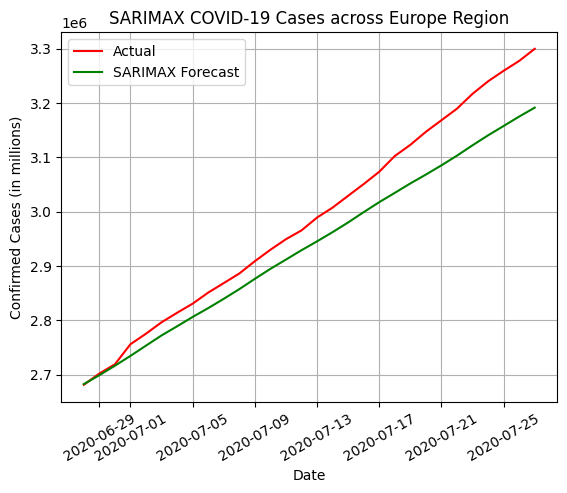

In [31]:
train_Europe = Europe['confirmed'][:-30]
test_Europe = Europe['confirmed'][-30:]
Europe_model_SARIMAX = SARIMAX(train_Europe, order=(2,1,2), seasonal_order=(1,1,1,7))
Europe_SARIMAX_result=Europe_model_SARIMAX.fit()

Europe_forecasting_SARIMAX =Europe_SARIMAX_result.forecast(steps=30)
Europe_forecasting_SARIMAX.index = test_Europe.index

plt.plot(test_Europe.index, test_Europe, label='Actual', color='red')
plt.plot(Europe_forecasting_SARIMAX.index,Europe_forecasting_SARIMAX, label='SARIMAX Forecast', linestyle='-', color='green')
plt.title('SARIMAX COVID-19 Cases across Europe Region')
plt.xlabel('Date')
plt.ylabel('Confirmed Cases (in millions)')
plt.legend()
plt.grid(True)
plt.xticks(rotation=30)

plt.show()

In [32]:
SARIMAX___mse = mean_squared_error(test_Europe, Europe_forecasting_SARIMAX)
SARIMAX___rmse = np.sqrt(SARIMAX___mse)
SARIMAX___mape = mean_absolute_percentage_error(test_Europe, Europe_forecasting_SARIMAX) * 100

print(f"RMSE: {SARIMAX___rmse:.4f}")
print(f"MAPE: {SARIMAX___mape:.4f}%")

RMSE: 58876.2305
MAPE: 1.6064%


The **ARIMA** and **SARIMAX** models were evaluated on the confirmed COVID-19 cases in the **Europe** region using **RMSE** and **MAPE**, which produced the following results:

**ARIMA** – RMSE: 59771.1948, MAPE: 1.6028%

**SARIMAX** – RMSE: 58876.2305, MAPE: 1.6064%

The two models performed almost identically: **SARIMAX** had a slightly lower RMSE, while **ARIMA** had a slightly lower MAPE.

My 2nd Host/Target Region is Africa.

In [33]:
Africa_df = df[df['who__region'] == 'Africa']
Africa = Africa_df.groupby('date')['confirmed'].sum().reset_index()
#To perform time-based indexing, I first converted the date column into datetime format.
#I then sorted the data to prepare it for the time series forecasting model and finally set the date column as the index for my ARIMA model to effectively capture trends and seasonality.
Africa['date'] = pd.to_datetime(Africa['date'])
Africa = Africa.sort_values('date')
Africa.set_index('date', inplace=True)

Time Series Forecasting with the ARIMA Model – generating predictions based on historical data patterns.

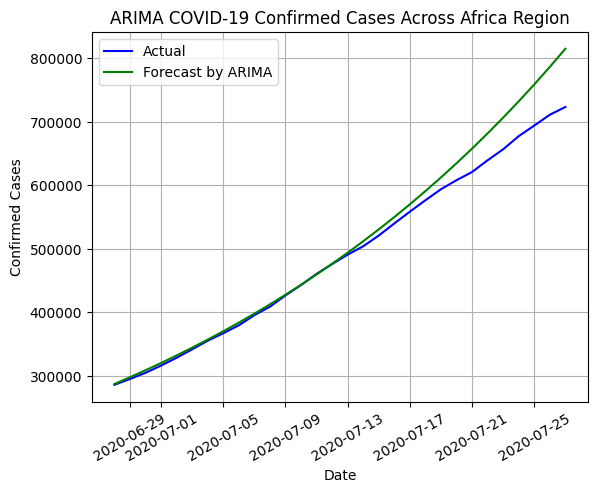

In [34]:
train_Africa = Africa[:-30]
test_Africa = Africa[-30:]

Africa_model_arima = ARIMA(train_Africa,order=(2,1,2),enforce_stationarity=False, enforce_invertibility=False)
Africa_result_arima = Africa_model_arima.fit()
forecast_arima_Africa = Africa_result_arima.forecast(steps=30)
forecast_arima_Africa.index = test_Africa.index

plt.plot(test_Africa.index, test_Africa, label='Actual', color='blue')
plt.plot(test_Africa.index, forecast_arima_Africa, label='Forecast by ARIMA', linestyle='-', color='green')
plt.title('ARIMA COVID-19 Confirmed Cases Across Africa Region')
plt.xlabel('Date')
plt.ylabel('Confirmed Cases')
plt.legend()
plt.grid(True)
plt.xticks(rotation=30)
plt.show()

For assessing the ARIMA model, I used RMSE and MAPE to measure the accuracy of its forecasts.

In [35]:
ARIMA_mse_Africa = mean_squared_error(test_Africa, forecast_arima_Africa)
ARIMA_rmse_Africa = np.sqrt(ARIMA_mse_Africa)
ARIMA_mape_Africa = mean_absolute_percentage_error(test_Africa, forecast_arima_Africa)*100

print(f"RMSE: {ARIMA_rmse_Africa:.4f}")
print(f"MAPE: {ARIMA_mape_Africa:.4f}%")

RMSE: 30893.6138
MAPE: 2.9728%


Using **RMSE** and **MAPE**, I assessed the accuracy of the **ARIMA** model's forecasts. The same metrics were then applied to evaluate the **SARIMAX** model, so that both models could be compared on equal terms.

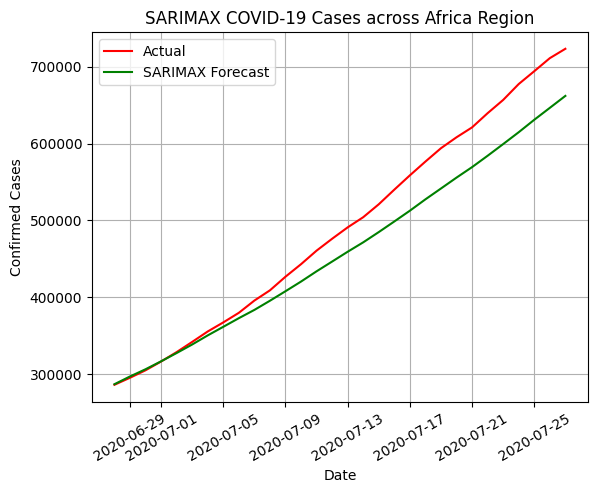

In [36]:
train_Africa =Africa[:-30]
test_Africa = Africa[-30:]
Africa_model_SARIMAX = SARIMAX(train_Africa, order=(2,1,2), seasonal_order=(1,1,1,7))
Africa_SARIMAX_result=Africa_model_SARIMAX.fit()

Africa_forecasting_SARIMAX =Africa_SARIMAX_result.forecast(steps=30)
Africa_forecasting_SARIMAX.index = test_Africa.index

plt.plot(test_Africa.index, test_Africa, label='Actual', color='red')
plt.plot(Africa_forecasting_SARIMAX.index,Africa_forecasting_SARIMAX, label='SARIMAX Forecast', linestyle='-', color='green')
plt.title('SARIMAX COVID-19 Cases across Africa Region')
plt.xlabel('Date')
plt.ylabel('Confirmed Cases')
plt.legend()
plt.grid(True)
plt.xticks(rotation=30)

plt.show()

For assessing the accuracy of the SARIMAX model, I used RMSE and MAPE as evaluation metrics.

In [37]:
mse_SARIMAX_Africa = mean_squared_error(test_Africa, Africa_forecasting_SARIMAX)
rmse_SARIMAX_Africa = np.sqrt(mse_SARIMAX_Africa)
mape_SARIMAX_Africa = mean_absolute_percentage_error(test_Africa, Africa_forecasting_SARIMAX)*100

print(f"RMSE: {rmse_SARIMAX_Africa:.4f}")
print(f"MAPE: {mape_SARIMAX_Africa:.4f}%")

RMSE: 37824.6682
MAPE: 5.2961%


The **ARIMA** and **SARIMAX** models were evaluated on the confirmed COVID-19 cases in the **Africa** region using **RMSE** and **MAPE**, which produced the following results:

**ARIMA** – RMSE: 30893.6138, MAPE: 2.9728%

**SARIMAX** – RMSE: 37824.6682, MAPE: 5.2961%

**ARIMA** achieved the lower error on both metrics, so it performed better than **SARIMAX** for this region.

For this analysis, the Americas has been designated as the 3rd host/target region.

In [38]:
Americas_df= df[df['who__region'] == 'Americas']

Americas = Americas_df.groupby('date')['confirmed'].sum().reset_index()
#As i have to perform time based indexing so i converted the date column into datetime format,after which i sorted the data due to working with time series forecasting model.
#Lastly,i set the date as index for my ARIMA model to detect the trend and seasonality.
Americas['date'] = pd.to_datetime(Americas['date'])
Americas = Americas.sort_values('date')
Americas.set_index('date', inplace=True)

Time Series Forecasting with the ARIMA Model – generating predictions based on historical data trends.

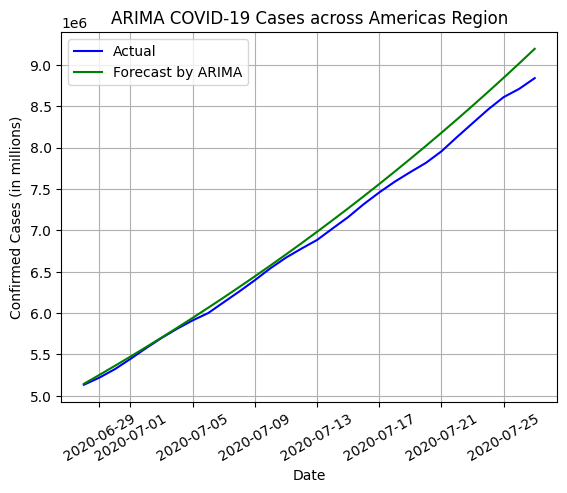

In [39]:
train_Americas = Americas[:-30]
test_Americas = Americas[-30:]
Americas_model_arima = ARIMA(train_Americas,order=(2,1,2),enforce_stationarity=False, enforce_invertibility=False)
Americas_result_arima = Americas_model_arima.fit()
forecast_arima_Americas = Americas_result_arima.forecast(steps=30)
forecast_arima_Americas.index = test_Americas.index

plt.plot(test_Americas.index, test_Americas, label='Actual', color='blue')
plt.plot(test_Americas.index, forecast_arima_Americas, label='Forecast by ARIMA', linestyle='-', color='green')
plt.title('ARIMA COVID-19 Cases across Americas Region')
plt.xlabel('Date')
plt.ylabel('Confirmed Cases (in millions)')
plt.legend()
plt.grid(True)

#The date labels in the output were overlapping; to improve clarity, I rotated the labels to a suitable angle.
plt.xticks(rotation=30)
plt.show()

For assessing the ARIMA model, I used RMSE and MAPE as evaluation metrics to measure the accuracy of its forecasts.

In [40]:
Americas_ARIMA__mse = mean_squared_error(test_Americas, forecast_arima_Americas)
Americas_ARIMA__rmse = np.sqrt(Americas_ARIMA__mse)
Americas_ARIMA__mape = mean_absolute_percentage_error(test_Americas, forecast_arima_Americas)*100

print(f"RMSE: {Americas_ARIMA__rmse:.4f}")
print(f"MAPE: {Americas_ARIMA__mape:.4f}%")

RMSE: 143537.5084
MAPE: 1.4305%


Using RMSE and MAPE, I assessed the accuracy of the ARIMA model’s forecasts. I will now apply the same metrics to evaluate the SARIMAX model.

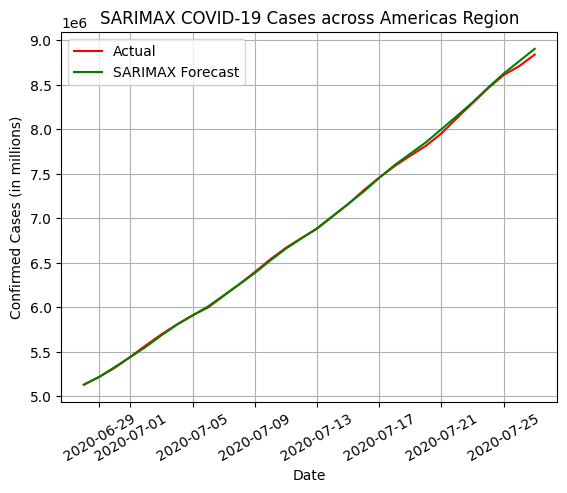

In [41]:
train_Americas =Americas[:-30]
test_Americas = Americas[-30:]
Americas_model_SARIMAX = SARIMAX(train_Americas, order=(2,1,2), seasonal_order=(1,1,1,7))
Americas_SARIMAX_result=Americas_model_SARIMAX.fit()

Americas_forecasting_SARIMAX =Americas_SARIMAX_result.forecast(steps=30)
Americas_forecasting_SARIMAX.index = test_Americas.index

plt.plot(test_Americas.index, test_Americas, label='Actual', color='red')
plt.plot(Americas_forecasting_SARIMAX.index,Americas_forecasting_SARIMAX, label='SARIMAX Forecast', linestyle='-', color='green')
plt.title('SARIMAX COVID-19 Cases across Americas Region')
plt.xlabel('Date')
plt.ylabel('Confirmed Cases (in millions)')
plt.legend()
plt.grid(True)
plt.xticks(rotation=30)

plt.show()

For the assessment of the SARIMAX model, I employed RMSE and MAPE as evaluation metrics to measure its forecasting accuracy.

In [42]:
Americas_mse_SARIMAX = mean_squared_error(test_Americas, Americas_forecasting_SARIMAX)
Americas_rmse_SARIMAX = np.sqrt(Americas_mse_SARIMAX)
Americas_mape_SARIMAX = mean_absolute_percentage_error(test_Americas, Americas_forecasting_SARIMAX)*100

print(f"RMSE: {Americas_rmse_SARIMAX:.4f}")
print(f"MAPE: {Americas_mape_SARIMAX:.4f}%")

RMSE: 21602.3686
MAPE: 0.1906%


The **ARIMA** and **SARIMAX** models were evaluated on the confirmed COVID-19 cases in the **Americas** region using **RMSE** and **MAPE**, which produced the following results:

**ARIMA** – RMSE: 143537.5084, MAPE: 1.4305%

**SARIMAX** – RMSE: 21602.3686, MAPE: 0.1906%

**SARIMAX** achieved the lower error on both metrics, so it performed better than **ARIMA** for this region.

For easier comparison, I am creating a table that summarizes the RMSE and MAPE values of both the ARIMA and SARIMAX models for all WHO regions, providing a clear overview of model performance.

In [43]:
Comparing_Region = {'WHO Regions': ['Europe', 'Africa', 'Americas'],
        'ARIMA RMSE': [59771.1948, 30893.6138,143537.5084],
        'ARIMA MAPE(%)': [1.6028, 2.9728, 1.4305],
        'SARIMAX RMSE': [58876.2305, 37824.6682,21602.3686],
        'SARIMAX MAPE(%)': [1.6064, 5.2961,0.1906]}

The table, originally created as a Python dictionary, was converted into a DataFrame to facilitate visualization and improve its readability and professional presentation.

In [44]:
Regions_df = pd.DataFrame(Comparing_Region)

In [45]:
print(Regions_df)

  WHO Regions   ARIMA RMSE  ARIMA MAPE(%)  SARIMAX RMSE  SARIMAX MAPE(%)
0      Europe   59771.1948         1.6028    58876.2305           1.6064
1      Africa   30893.6138         2.9728    37824.6682           5.2961
2    Americas  143537.5084         1.4305    21602.3686           0.1906


These values can be effectively visualized with a bar chart, allowing for a clear comparison between the metrics.

To analyze model accuracy, I created a bar chart displaying the **RMSE** values of **ARIMA** and **SARIMAX** across each WHO region.

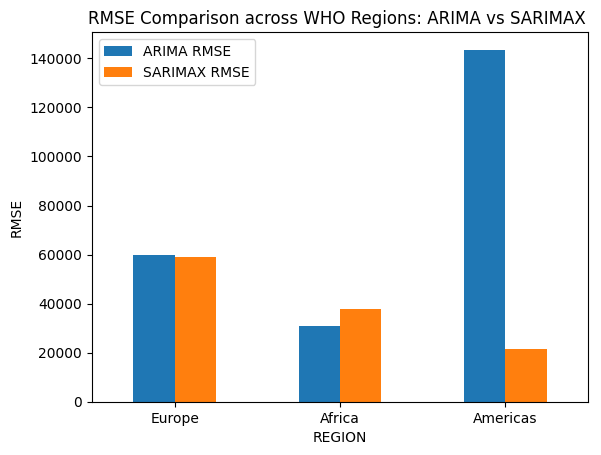

In [46]:
Regions_df.plot(
    x='WHO Regions',
    y=['ARIMA RMSE', 'SARIMAX RMSE'],
    kind='bar'
)
plt.title('RMSE Comparison across WHO Regions: ARIMA vs SARIMAX ')
plt.xlabel('REGION')
plt.ylabel('RMSE')
plt.xticks(rotation=360)
plt.show()

To visually compare model performance, I am creating a bar chart illustrating the MAPE values for ARIMA and SARIMAX across each WHO region.

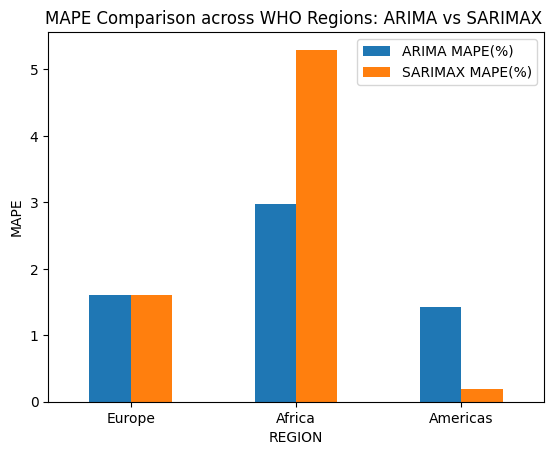

In [47]:
Regions_df.plot(
    x='WHO Regions',
    y=['ARIMA MAPE(%)', 'SARIMAX MAPE(%)'],
    kind='bar'
)
plt.title('MAPE Comparison across WHO Regions: ARIMA vs SARIMAX ')
plt.xlabel('REGION')
plt.ylabel('MAPE')
plt.xticks(rotation=360)
plt.show()

The following key observations were made from the table and visualization:

* **Africa** showed the highest **MAPE** for both ARIMA and SARIMAX, even though its **RMSE** values were lower than those of Europe and of the Americas under ARIMA. The absolute errors were relatively small, but they were a large share of Africa's smaller case totals, so the percentage errors were higher.
* In the **Americas**, SARIMAX improved clearly on ARIMA, with lower RMSE and MAPE, which suggested that the seasonal component helped for this region.
* In **Europe**, ARIMA and SARIMAX produced nearly identical RMSE and MAPE values, suggesting that seasonality had minimal impact on the forecast for this region.

In conclusion, **SARIMAX** was the more accurate model in the **Americas**, both models performed similarly in **Europe**, and **ARIMA** achieved better accuracy in **Africa**, as indicated by lower **MAPE** values.

**Comparison of ARIMA and SARIMAX: Which Model Suits This Time Series Data Better?**

The analysis drew on the table and visualization prepared earlier, which served as the reference for the observations that follow.

An additional column was added to the referenced table to specify the better-suited model for each region, based on the earlier evaluation results.

In [48]:
Comparing_Region = {'WHO Regions': ['Europe', 'Africa', 'Americas'],
        'ARIMA RMSE': [59771.1948, 30893.6138,143537.5084],
        'ARIMA MAPE(%)': [1.6028, 2.9728, 1.4305],
        'SARIMAX RMSE': [58876.2305, 37824.6682,21602.3686],
        'SARIMAX MAPE(%)': [1.6064, 5.2961,0.1906],
        'Better Suited Model': ['ARIMA','ARIMA','SARIMAX'],}
Regions_df = pd.DataFrame(Comparing_Region)
print(Regions_df)

  WHO Regions   ARIMA RMSE  ARIMA MAPE(%)  SARIMAX RMSE  SARIMAX MAPE(%)  \
0      Europe   59771.1948         1.6028    58876.2305           1.6064   
1      Africa   30893.6138         2.9728    37824.6682           5.2961   
2    Americas  143537.5084         1.4305    21602.3686           0.1906   

  Better Suited Model  
0               ARIMA  
1               ARIMA  
2             SARIMAX  


The previously created visualization is provided here for reference, and it remains unchanged from the original version.

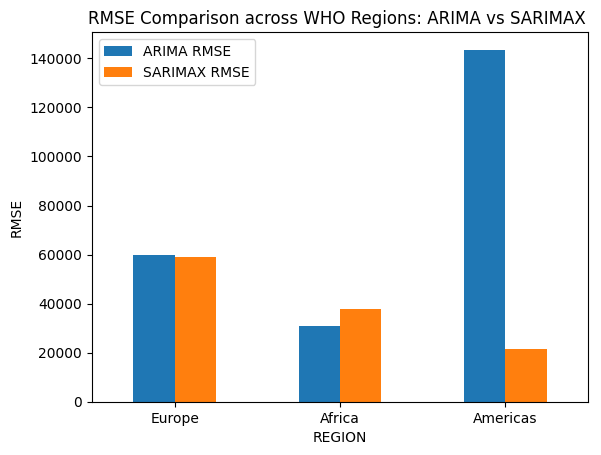






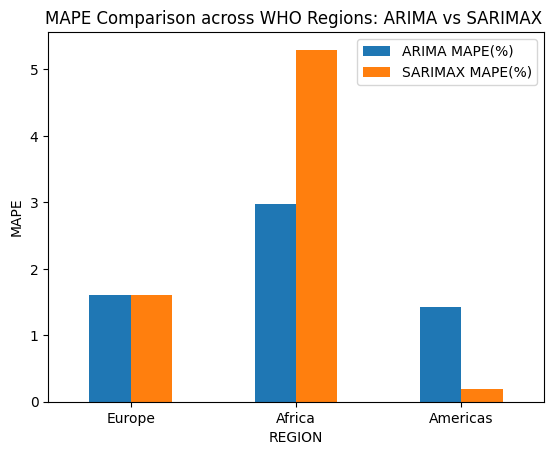

The **MAPE** analysis showed that **ARIMA** performed better than **SARIMAX** in Europe and Africa, suggesting that ARIMA alone captured the COVID-19 case trends in these regions without requiring additional seasonal adjustments.

#**Summary of Approach, Findings, and Recommendations**

This section summarized the methodology, key observations, and recommendations drawn from the data analysis and modeling. It covered the approach used for forecasting COVID-19 cases, the insights obtained from comparing the **ARIMA** and **SARIMAX** models across regions, and actionable recommendations for improving **model performance** in time series forecasting.

**Approach**

The project applied the **ARIMA** and **SARIMAX** time series models to analyze and forecast confirmed COVID-19 cases.

The dataset was first cleaned and preprocessed, followed by **seasonal decomposition** to examine the trend and seasonality in the data.

Forecasts were then generated for **Japan** and for three WHO regions: **Europe**, **Africa**, and the **Americas**. Model performance was evaluated with **RMSE** and **MAPE**, which allowed the two models to be compared on each target.

**Key Findings:**

* The **ARIMA** model outperformed **SARIMAX** in Japan (MAPE 13.47% vs 21.02%), even though the decomposition showed a weekly seasonal pattern with a 7-day cycle.
* Forecasting performance differed across WHO regions. **SARIMAX** performed clearly better in the **Americas**, **ARIMA** performed better in **Africa**, and the two models performed almost identically in **Europe**.
* **Africa** recorded the highest percentage errors (MAPE of 2.97% for ARIMA and 5.30% for SARIMAX), whereas **SARIMAX** in the **Americas** produced the most accurate forecasts, with the lowest MAPE (0.19%) and RMSE (21,602) of all results.

#**Recommendations:**



*   **SARIMAX** is recommended over **ARIMA** when the data shows distinct seasonal patterns, as it captures both trend and seasonal components. In this project, ARIMA produced the lower error, so the seasonal pattern should be confirmed on daily case counts before choosing SARIMAX.
*   Given the dynamic nature of COVID-19 data, the models should be retrained at regular intervals to keep the predictions reliable and accurate.

*   Country-level analysis is important alongside regional analysis, since COVID-19 trends can differ significantly between countries.
*  Including relevant features like vaccination rates and other health indicators may help improve the predictive performance of the time series model.










